# Assignment 1 — Data Profiling (EDA) Report

**Dataset:** UCI Online Retail  
**Team:** ZHANG KAIYI (A207404); YANG LIZIXUAN (A207402); YUAN YIWEI (A207421); ZHOU XIUSHI (A207418)

This notebook profiles transaction data and documents quality decisions. It does not train a model.


## 1. Scenario

A UK-based online retailer records product lines for transactions, including cancellations and customers from several countries. This open dataset is suitable for profiling because transaction records can have missing identifiers or descriptions, extreme quantities and prices, and inconsistent business meaning. The main questions are which rows represent usable completed sales, which unusual values are legitimate, and what privacy or country-coverage limits remain.


## 2. Data source and field meanings

**Source:** [UCI Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail), dataset ID 352, DOI [10.24432/C5BW33](https://doi.org/10.24432/C5BW33). UCI describes transactions from 1 December 2010 to 9 December 2011 for a UK-based online retailer. The original `Online Retail.xlsx` is stored in `data/`; if it is absent, the next cell downloads UCI's official ZIP and extracts the workbook. No synthetic rows or deliberately introduced defects are used. Dataset credit: Chen, D. (2015), *Online Retail*, UCI Machine Learning Repository, CC BY 4.0.

| Field | Meaning |
|---|---|
| InvoiceNo | Transaction invoice number; a leading `C` indicates a cancellation |
| StockCode | Product code |
| Description | Product description |
| Quantity | Item quantity on the transaction line |
| InvoiceDate | Transaction date and time |
| UnitPrice | Price per item in pounds sterling |
| CustomerID | Customer identifier; potentially linkable to a person |
| Country | Customer's country |

**Unit of observation:** one workbook row is a product line, not necessarily one unique invoice or customer. Counts and country shares below are therefore *row shares*. Source metadata may differ from missing values observed in the workbook; the workbook itself is profiled below.


In [1]:
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile
from io import BytesIO
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

%matplotlib inline
sns.set_theme(style="whitegrid")
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
DATA_FILE = DATA_DIR / "Online Retail.xlsx"
UCI_PAGE = "https://archive.ics.uci.edu/dataset/352/online+retail"
UCI_ZIP = "https://archive.ics.uci.edu/static/public/352/online%2Bretail.zip"

if not DATA_FILE.exists():
    try:
        with urlopen(UCI_ZIP, timeout=120) as response:
            archive_bytes = response.read()
        with ZipFile(BytesIO(archive_bytes)) as archive:
            names = [name for name in archive.namelist() if name.lower().endswith("online retail.xlsx")]
            if len(names) != 1:
                raise ValueError(f"Expected one Online Retail workbook; found {names}")
            DATA_FILE.write_bytes(archive.read(names[0]))
        print(f"Downloaded the original workbook from {UCI_ZIP}")
    except Exception as exc:
        raise RuntimeError(
            f"Could not download the official UCI workbook: {exc}. "
            f"Open {UCI_PAGE}, click Download, extract 'Online Retail.xlsx' "
            f"and place it at {DATA_FILE.resolve()}, then rerun this cell."
        ) from exc
print(f"Using original UCI workbook: {DATA_FILE} ({DATA_FILE.stat().st_size:,} bytes)")
raw_df = pd.read_excel(DATA_FILE, engine="openpyxl")
assert len(raw_df) > 0 and len(raw_df.columns) == 8, "Unexpected workbook shape."
print(f"Original records: {len(raw_df):,}")


Using original UCI workbook: data\Online Retail.xlsx (23,715,344 bytes)


Original records: 541,909


## 3. Initial profiling of untouched data

The following checks use `raw_df` exactly as read from the workbook. In particular, missing values and exact duplicates are counted before any cleaning decision. Pandas may infer `CustomerID` as a floating type because of blanks; that does not make it a numerical measurement.


In [2]:
print("Shape (rows, columns):", raw_df.shape)
sample_rows = raw_df.head(5).copy()
sample_rows["CustomerID"] = sample_rows["CustomerID"].map(
    lambda value: "<present>" if pd.notna(value) else "<missing>"
)
display(sample_rows)
print("Column names:", list(raw_df.columns))
display(raw_df.dtypes.rename("inferred dtype").to_frame())
display(raw_df.describe(include="all").T)
raw_missing = raw_df.isna().sum()
raw_missing_pct = raw_missing.div(len(raw_df)).mul(100)
display(pd.DataFrame({"Missing rows": raw_missing, "Missing %": raw_missing_pct.round(2)}))
raw_duplicate_count = int(raw_df.duplicated().sum())
print(f"Exact duplicate rows beyond first occurrence: {raw_duplicate_count:,} "
      f"({raw_duplicate_count / len(raw_df):.2%})")


Shape (rows, columns): (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,<present>,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,<present>,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,<present>,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,<present>,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,<present>,United Kingdom


Column names: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,inferred dtype
InvoiceNo,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[us]
UnitPrice,float64
CustomerID,float64
Country,str


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,Missing rows,Missing %
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


Exact duplicate rows beyond first occurrence: 5,268 (0.97%)


## 4. Missing-value analysis and policy

The workbook is a line-level transaction file. A missing `CustomerID` prevents customer-level work but does not necessarily invalidate a product sale; it is flagged and never filled with a fabricated ID. A missing or blank `Description` prevents reliable product interpretation, so such lines remain visible in the audit copy and are excluded from the sales-ready view. No global imputation is justified. The checks below inspect every original field and then recompute missingness after the sales-view selection.


In [3]:
audit_df = raw_df.copy(deep=True)
audit_df["InvoiceNo"] = audit_df["InvoiceNo"].astype("string").str.strip()
audit_df["StockCode"] = audit_df["StockCode"].astype("string").str.strip()
audit_df["Description"] = audit_df["Description"].astype("string").str.strip()
audit_df["Country"] = audit_df["Country"].astype("string").str.strip()
audit_df["InvoiceDate"] = pd.to_datetime(audit_df["InvoiceDate"], errors="coerce")
audit_df["Quantity"] = pd.to_numeric(audit_df["Quantity"], errors="coerce")
audit_df["UnitPrice"] = pd.to_numeric(audit_df["UnitPrice"], errors="coerce")
audit_df["CustomerID_present"] = audit_df["CustomerID"].notna()
audit_df["Description_missing"] = audit_df["Description"].isna() | audit_df["Description"].eq("").fillna(False)
audit_df["InvoiceDate_invalid"] = audit_df["InvoiceDate"].isna()
audit_df["InvoiceNo_missing"] = audit_df["InvoiceNo"].isna() | audit_df["InvoiceNo"].eq("").fillna(False)
audit_df["StockCode_missing"] = audit_df["StockCode"].isna() | audit_df["StockCode"].eq("").fillna(False)
audit_df["Country_missing"] = audit_df["Country"].isna() | audit_df["Country"].eq("").fillna(False)
display(pd.DataFrame({"Missing rows": raw_missing,
                      "Missing %": raw_missing_pct.round(2)}))
display(Markdown(
    f"The raw workbook has **{raw_missing['CustomerID']:,}** missing customer IDs "
    f"({raw_missing_pct['CustomerID']:.2f}%) and **{raw_missing['Description']:,}** "
    f"missing product descriptions ({raw_missing_pct['Description']:.2f}%). "
    "Customer IDs are not imputed. Descriptions are not invented."
))


,Missing rows,Missing %
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


The raw workbook has **135,080** missing customer IDs (24.93%) and **1,454** missing product descriptions (0.27%). Customer IDs are not imputed. Descriptions are not invented.

## 5. Outlier detection and handling

IQR fences are a diagnostic rule, not a business-validity rule. They are calculated on the original `Quantity` and `UnitPrice` columns, including cancellations and zero-price records, so they show the unmodified distribution. Negative quantities can represent cancellation/return activity; large positive quantities or prices can be genuine wholesale transactions. We retain extreme positive values in the sales view and separate invalid or cancelled lines through explicit business rules below. We do not cap values merely to make boxplots look tidy.


,Q1,Q3,IQR,Lower bound,Upper bound,Outlier rows,Outlier %
Quantity,1.00,10.00,9.00,-12.50,23.50,58619.0,10.82
UnitPrice,1.25,4.13,2.88,-3.07,8.45,39627.0,7.31


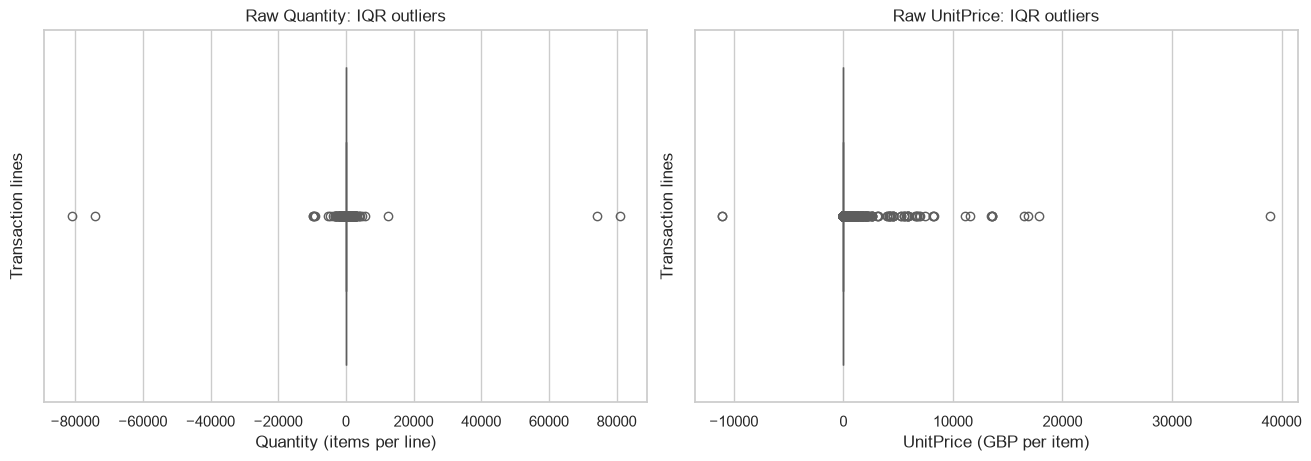

The IQR rule flags **58,619** quantity rows and **39,627** price rows. The long tails compress the boxes; flagged rows require business context, so positive extremes are kept rather than automatically deleted.

In [4]:
def iqr_profile(series):
    values = pd.to_numeric(series, errors="coerce").dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = int(((values < lower) | (values > upper)).sum())
    return {"Q1": q1, "Q3": q3, "IQR": iqr, "Lower bound": lower,
            "Upper bound": upper, "Outlier rows": count,
            "Outlier %": 100 * count / len(values)}

outlier_table = pd.DataFrame({name: iqr_profile(raw_df[name])
                              for name in ["Quantity", "UnitPrice"]}).T
display(outlier_table.round(2))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
for ax, field in zip(axes, ["Quantity", "UnitPrice"]):
    sns.boxplot(x=raw_df[field], ax=ax, color="#6ca5ce", showfliers=True)
    ax.set_title(f"Raw {field}: IQR outliers")
    ax.set_xlabel(field + (" (items per line)" if field == "Quantity" else " (GBP per item)"))
    ax.set_ylabel("Transaction lines")
plt.show()
display(Markdown(
    f"The IQR rule flags **{int(outlier_table.loc['Quantity', 'Outlier rows']):,}** "
    f"quantity rows and **{int(outlier_table.loc['UnitPrice', 'Outlier rows']):,}** "
    "price rows. The long tails compress the boxes; flagged rows require business context, "
    "so positive extremes are kept rather than automatically deleted."
))


## 6. Other quality issues and sales-view rules

- **Exact duplicates:** Rows identical in all original columns are flagged. Because the source lacks a line-item key, identical rows could be repeated products on an invoice. Automatic deduplication might erase genuine quantity, so no duplicate is removed without source-system confirmation.
- **Types and text:** Invoice/product codes are categorical strings, the date is parsed to `datetime`, numeric measures are converted with coercion, and surrounding whitespace is stripped from text. Country labels are not remapped without verified equivalences (for example, `EIRE` is retained as supplied).
- **Descriptions:** Missing or blank product names are marked and excluded from the *sales-ready* view; they remain in `audit_df` for investigation.
- **Transactions:** An invoice beginning with `C` is treated as cancelled. A non-cancelled line with non-positive quantity, non-positive price, missing core code/date/country, or missing description is excluded from the sales-ready view. Cancellations and excluded rows remain in `audit_df`. Zero price could represent a promotion or adjustment, but it cannot support standard revenue calculations without context; it is not called a proven recording error.
- **Extremes:** Positive IQR outliers are retained. These rules define a conservative completed-sales view, not a repaired version of all transaction history.


In [5]:
audit_df["Exact_duplicate"] = raw_df.duplicated(keep="first")
audit_df["Cancelled_invoice"] = audit_df["InvoiceNo"].str.upper().str.startswith("C").fillna(False)
audit_df["Nonpositive_quantity"] = audit_df["Quantity"].isna() | audit_df["Quantity"].le(0)
audit_df["Nonpositive_price"] = audit_df["UnitPrice"].isna() | audit_df["UnitPrice"].le(0)
audit_df["Invalid_sales_line"] = (
    audit_df["Description_missing"] | audit_df["InvoiceDate_invalid"] |
    audit_df["InvoiceNo_missing"] | audit_df["StockCode_missing"] |
    audit_df["Country_missing"] | audit_df["Nonpositive_quantity"] |
    audit_df["Nonpositive_price"]
)
audit_df["Sales_eligible"] = ~audit_df["Cancelled_invoice"] & ~audit_df["Invalid_sales_line"]

issue_counts = pd.Series({
    "Exact duplicate rows": int(audit_df["Exact_duplicate"].sum()),
    "Missing or blank descriptions": int(audit_df["Description_missing"].sum()),
    "Cancelled invoice rows": int(audit_df["Cancelled_invoice"].sum()),
    "Negative quantity rows": int(audit_df["Quantity"].lt(0).sum()),
    "Zero quantity rows": int(audit_df["Quantity"].eq(0).sum()),
    "Zero price rows": int(audit_df["UnitPrice"].eq(0).sum()),
    "Negative price rows": int(audit_df["UnitPrice"].lt(0).sum()),
    "Invalid date rows": int(audit_df["InvoiceDate_invalid"].sum()),
    "Non-cancelled invalid sales lines": int((~audit_df["Cancelled_invoice"] & audit_df["Invalid_sales_line"]).sum()),
}, name="Rows")
display(issue_counts.to_frame())
sales_df = audit_df.loc[audit_df["Sales_eligible"],
    ["InvoiceNo", "StockCode", "Description", "Quantity", "InvoiceDate",
     "UnitPrice", "Country", "CustomerID_present"]].copy()
assert len(raw_df) == len(audit_df), "The audit copy must retain every raw row."
assert len(sales_df) + int((~audit_df["Sales_eligible"]).sum()) == len(raw_df)
display(Markdown(
    f"**{len(sales_df):,}** of **{len(raw_df):,}** lines are eligible for the "
    "completed-sales view. Exclusions overlap across quality flags; the final count "
    "uses one combined mask. The sales view omits raw `CustomerID`."
))


,Rows
Exact duplicate rows,5268
Missing or blank descriptions,1454
Cancelled invoice rows,9288
Negative quantity rows,10624
Zero quantity rows,0
Zero price rows,2515
Negative price rows,2
Invalid date rows,0
Non-cancelled invalid sales lines,2517


**530,104** of **541,909** lines are eligible for the completed-sales view. Exclusions overlap across quality flags; the final count uses one combined mask. The sales view omits raw `CustomerID`.

## 7. Diagnostic visualizations

The outlier boxplots above are the first labeled diagnostic figure. The next two figures show missingness and country coverage. These are quality and representativeness checks, not revenue or performance dashboards.


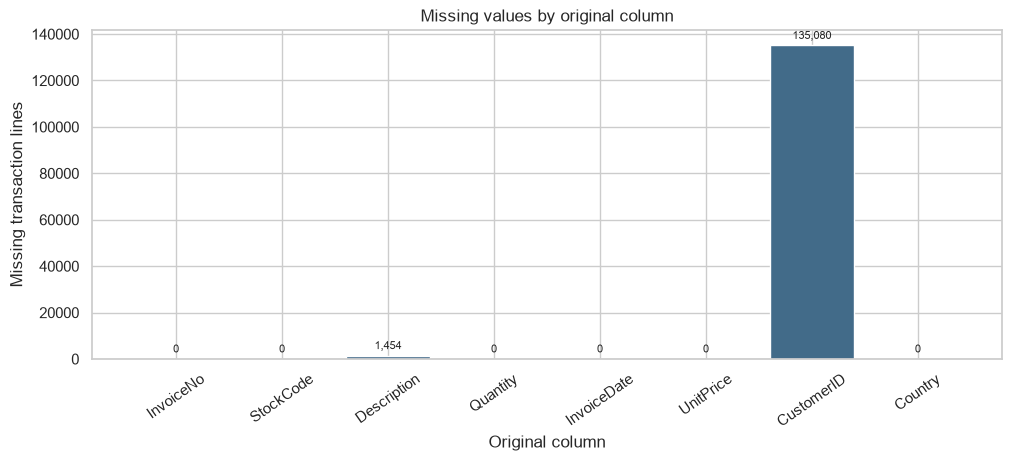

Missingness is concentrated in customer IDs and descriptions. The sales view has **0** missing values across its retained columns; customer-ID availability remains a separate flag.

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.5), constrained_layout=True)
bars = ax.bar(raw_missing.index, raw_missing.values, color="#426b89")
ax.bar_label(bars, labels=[f"{n:,}" for n in raw_missing], padding=3, fontsize=8)
ax.set_title("Missing values by original column")
ax.set_xlabel("Original column")
ax.set_ylabel("Missing transaction lines")
ax.tick_params(axis="x", rotation=35)
plt.show()
display(Markdown(
    "Missingness is concentrated in customer IDs and descriptions. "
    f"The sales view has **{int(sales_df.isna().sum().sum()):,}** missing values "
    "across its retained columns; customer-ID availability remains a separate flag."
))


,Rows,Row share %
Country,,
United Kingdom,495478,91.43
Germany,9495,1.75
France,8557,1.58
EIRE,8196,1.51
Spain,2533,0.47
Netherlands,2371,0.44
Belgium,2069,0.38
Switzerland,2002,0.37
Portugal,1519,0.28


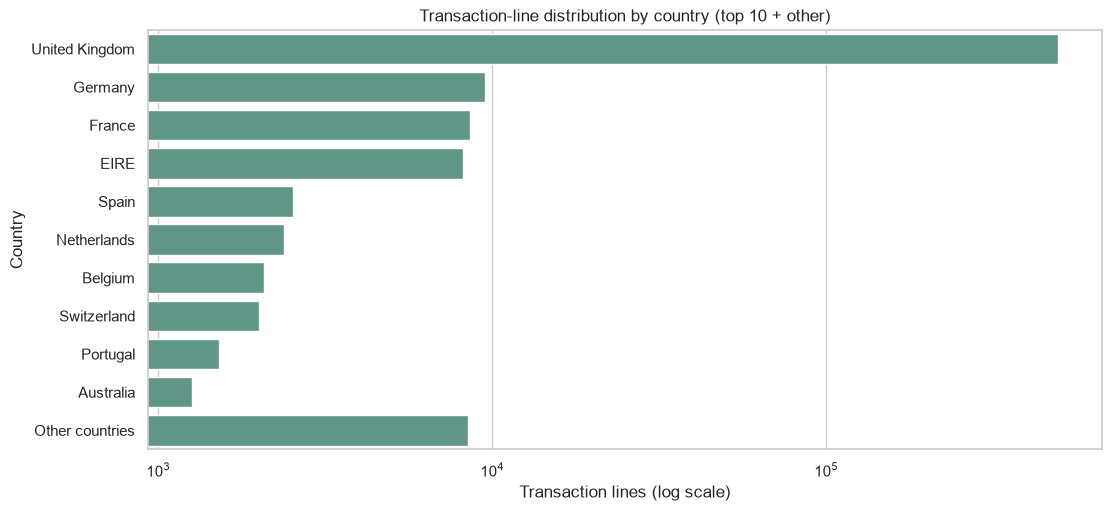

The largest country accounts for **91.43%** of original rows (United Kingdom). This concentration limits generalization to other countries; it does not by itself prove discrimination. The logarithmic axis keeps smaller country groups visible.

In [7]:
country_counts = raw_df["Country"].fillna("<missing>").value_counts()
country_shares = country_counts.div(len(raw_df)).mul(100)
display(pd.DataFrame({"Rows": country_counts, "Row share %": country_shares.round(2)}))
top_n = 10
plot_counts = country_counts.head(top_n).copy()
if len(country_counts) > top_n:
    plot_counts.loc["Other countries"] = country_counts.iloc[top_n:].sum()
fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
sns.barplot(x=plot_counts.values, y=plot_counts.index, ax=ax, color="#579f8c")
ax.set_xscale("log")
ax.set_title("Transaction-line distribution by country (top 10 + other)")
ax.set_xlabel("Transaction lines (log scale)")
ax.set_ylabel("Country")
plt.show()
display(Markdown(
    f"The largest country accounts for **{country_shares.iloc[0]:.2f}%** "
    f"of original rows ({country_counts.index[0]}). This concentration limits "
    "generalization to other countries; it does not by itself prove discrimination. "
    "The logarithmic axis keeps smaller country groups visible."
))


## 8. PII and bias risks

`CustomerID` is a pseudonymous-looking identifier, not necessarily direct PII by itself. If linked with account or purchase-history data, it may enable re-identification. Raw identifiers should be access restricted; if customer-level work is approved, a controlled pseudonymization map can replace them and be stored separately. This notebook exposes only aggregate missingness and a boolean availability flag in `sales_df`, not customer identifiers in the cleaned output.

Country is both a useful coverage variable and a possible source of geographic or sampling bias. The country shares above measure line counts, not unique customers, invoices, or population rates. The UK retailer's clientele, wholesale mix, time window, and missing customer IDs constrain comparisons; a country imbalance alone is not evidence of unfair treatment. Country-stratified checks and additional data would be needed before extending conclusions beyond this retailer.


## 9. Data-quality summary and before/after comparison

Findings are calculated from the workbook. Rows can have several flags, so issue counts should not be summed to reconstruct the number excluded. The audit copy is retained; `sales_df` is a purpose-specific selection.


In [8]:
summary = pd.DataFrame([
    ["CustomerID missing", "isna()", f"{raw_missing['CustomerID']:,} rows ({raw_missing_pct['CustomerID']:.2f}%)", "Flag availability; omit ID from sales view", "Sale can exist without customer identity; avoid fabrication and exposure"],
    ["Description missing/blank", "isna() or empty after trim", f"{issue_counts['Missing or blank descriptions']:,} rows", "Exclude from sales view; retain in audit", "Product meaning cannot be checked"],
    ["Quantity IQR outliers", "1.5 × IQR fences", f"{int(outlier_table.loc['Quantity', 'Outlier rows']):,} rows", "Retain positive extremes; separate cancellations", "Wholesale quantities may be valid"],
    ["UnitPrice IQR outliers", "1.5 × IQR fences", f"{int(outlier_table.loc['UnitPrice', 'Outlier rows']):,} rows", "Retain valid positive extremes", "High prices alone do not prove error"],
    ["Exact duplicates", "duplicated() across source columns", f"{raw_duplicate_count:,} rows", "Flag; do not delete", "No line-item key to prove redundancy"],
    ["Cancelled invoices", "InvoiceNo begins with C", f"{issue_counts['Cancelled invoice rows']:,} rows", "Exclude from completed-sales view", "Cancellation is a different transaction event"],
    ["Non-positive quantity/price", "Numeric comparison", f"{issue_counts['Negative quantity rows']:,} negative quantities; {int(issue_counts['Zero price rows'] + issue_counts['Negative price rows']):,} non-positive prices", "Exclude from completed-sales view", "Not valid for ordinary positive sales totals without context"],
    ["Type/text consistency", "dtype, parse, strip", f"{issue_counts['Invalid date rows']:,} unparseable dates", "Parse dates; normalize surrounding spaces", "Consistent types and labels support checks"],
    ["Country concentration", "value_counts(normalize=True)", f"{country_shares.iloc[0]:.2f}% of rows in {country_counts.index[0]}", "Report limitation", "Coverage is not geographically representative"],
], columns=["Issue", "Detection Method", "Finding", "Action Taken", "Justification"])
display(summary)
comparison = pd.DataFrame({
    "Measure": ["Rows", "Missing values in comparable columns", "CustomerID missing", "Exact duplicate rows", "Non-cancelled invalid sales lines"],
    "Original workbook": [len(raw_df), int(raw_df[[col for col in raw_df.columns if col in sales_df.columns]].isna().sum().sum()),
                          int(raw_missing["CustomerID"]), raw_duplicate_count,
                          int(issue_counts["Non-cancelled invalid sales lines"])],
    "Sales-ready view": [len(sales_df), int(sales_df.isna().sum().sum()), "ID omitted; availability flag retained",
                         int(sales_df.duplicated().sum()), 0],
})
display(comparison)
print("Sales-view missing counts:")
display(sales_df.isna().sum().rename("Missing rows").to_frame())


,Issue,Detection Method,Finding,Action Taken,Justification
0,CustomerID missing,isna(),"135,080 rows (24.93%)",Flag availability; omit ID from sales view,Sale can exist without customer identity; avoi...
1,Description missing/blank,isna() or empty after trim,"1,454 rows",Exclude from sales view; retain in audit,Product meaning cannot be checked
2,Quantity IQR outliers,1.5 × IQR fences,"58,619 rows",Retain positive extremes; separate cancellations,Wholesale quantities may be valid
3,UnitPrice IQR outliers,1.5 × IQR fences,"39,627 rows",Retain valid positive extremes,High prices alone do not prove error
4,Exact duplicates,duplicated() across source columns,"5,268 rows",Flag; do not delete,No line-item key to prove redundancy
5,Cancelled invoices,InvoiceNo begins with C,"9,288 rows",Exclude from completed-sales view,Cancellation is a different transaction event
6,Non-positive quantity/price,Numeric comparison,"10,624 negative quantities; 2,517 non-positive...",Exclude from completed-sales view,Not valid for ordinary positive sales totals w...
7,Type/text consistency,"dtype, parse, strip",0 unparseable dates,Parse dates; normalize surrounding spaces,Consistent types and labels support checks
8,Country concentration,value_counts(normalize=True),91.43% of rows in United Kingdom,Report limitation,Coverage is not geographically representative


,Measure,Original workbook,Sales-ready view
0,Rows,541909,530104
1,Missing values in comparable columns,1454,0
2,CustomerID missing,135080,ID omitted; availability flag retained
3,Exact duplicate rows,5268,5226
4,Non-cancelled invalid sales lines,2517,0


Sales-view missing counts:


,Missing rows
InvoiceNo,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
UnitPrice,0
Country,0
CustomerID_present,0


## 10. Conclusion

The final judgment below is generated from the measured rows. The sales-ready view is intended for **descriptive analysis of completed positive-price sales lines**, while the audit copy retains cancellations and suspect lines for further investigation. It should not be used as a complete record of returns, as proof that duplicate lines are errors, or as representative evidence for every country or customer.


In [9]:
excluded = len(raw_df) - len(sales_df)
display(Markdown(
    f"The original workbook contains **{len(raw_df):,}** transaction lines. "
    f"The sales-ready view contains **{len(sales_df):,}** lines after **{excluded:,}** "
    "lines were excluded by documented, overlapping rules. The main problems were "
    f"missing customer IDs ({raw_missing['CustomerID']:,}), missing or blank descriptions "
    f"({issue_counts['Missing or blank descriptions']:,}), exact duplicate rows "
    f"({raw_duplicate_count:,}), cancellations ({issue_counts['Cancelled invoice rows']:,}), "
    "and non-positive quantities or prices. Dates and text were normalized; missing "
    "customer IDs were flagged, and genuine-looking positive extremes were kept. "
    "**The selected view is fit for cautious descriptive sales analysis of completed, "
    "positive-price lines for this retailer and period.** It is not fit for customer-level "
    "analysis without further identity controls, nor for full net-revenue/returns analysis "
    "without reconciling cancellations and adjustments. Duplicate-line ambiguity, missing "
    f"identifiers, and a **{country_shares.iloc[0]:.2f}%** row share for "
    f"{country_counts.index[0]} remain important quality, privacy, and generalizability limits."
))


The original workbook contains **541,909** transaction lines. The sales-ready view contains **530,104** lines after **11,805** lines were excluded by documented, overlapping rules. The main problems were missing customer IDs (135,080), missing or blank descriptions (1,454), exact duplicate rows (5,268), cancellations (9,288), and non-positive quantities or prices. Dates and text were normalized; missing customer IDs were flagged, and genuine-looking positive extremes were kept. **The selected view is fit for cautious descriptive sales analysis of completed, positive-price lines for this retailer and period.** It is not fit for customer-level analysis without further identity controls, nor for full net-revenue/returns analysis without reconciling cancellations and adjustments. Duplicate-line ambiguity, missing identifiers, and a **91.43%** row share for United Kingdom remain important quality, privacy, and generalizability limits.